# Query expansion
Pseudo-relevance feedback with RM3 and expansion with similar terms from word2vec and GloVe. BM25 and DirichletLM on the stopwords and stemming index are the backbones, with the settings tuned in the first notebook. The expansion settings are tuned on dev and the final numbers are measured on test.

In [1]:
import gensim.downloader
import matplotlib.pyplot as plt
import pandas as pd
import pyterrier as pt
from pyterrier.measures import nDCG

from helpers import (RANKING_METRICS, build_retriever, clean_query_text, controls_for_model, load_best_parameters,
                     load_queries_and_qrels, milliseconds_per_query, open_index, save_results,
                     update_best_parameters)

if not pt.java.started():
    pt.java.init()

Java started and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]


In [2]:
dev_queries, dev_qrels = load_queries_and_qrels("dev")
test_queries, test_qrels = load_queries_and_qrels("test")

best_parameters = load_best_parameters()
index = open_index("stopwords_stemming")

bm25 = build_retriever(index, "BM25", controls_for_model("BM25", best_parameters["BM25"]))
dirichlet = build_retriever(index, "DirichletLM", controls_for_model("DirichletLM", best_parameters["DirichletLM"]))


def dev_ndcg(systems: list) -> list:
    names = [f"system {position}" for position in range(len(systems))]
    results = pt.Experiment(systems, dev_queries, dev_qrels, [nDCG @ 10], names=names)
    return results["nDCG@10"].tolist()

## RM3
The number of feedback terms is tuned first with 10 feedback documents, then the number of feedback documents with the best number of terms. This is tuned with BM25 and reused for DirichletLM.

In [3]:
FB_TERMS_VALUES = [1, 3, 5, 10, 20, 50, 100, 200]
FB_DOCS_VALUES = [1, 3, 5, 10, 20, 50]
FIXED_FB_DOCS = 10


def rm3_pipeline(retriever, fb_terms: int, fb_docs: int):
    return retriever >> pt.rewrite.RM3(index, fb_terms=fb_terms, fb_docs=fb_docs) >> retriever


terms_scores = dev_ndcg([rm3_pipeline(bm25, fb_terms, FIXED_FB_DOCS) for fb_terms in FB_TERMS_VALUES])
best_fb_terms = FB_TERMS_VALUES[terms_scores.index(max(terms_scores))]

docs_scores = dev_ndcg([rm3_pipeline(bm25, best_fb_terms, fb_docs) for fb_docs in FB_DOCS_VALUES])
best_fb_docs = FB_DOCS_VALUES[docs_scores.index(max(docs_scores))]

print("feedback terms:", best_fb_terms, "feedback documents:", best_fb_docs)

feedback terms: 200 feedback documents: 1


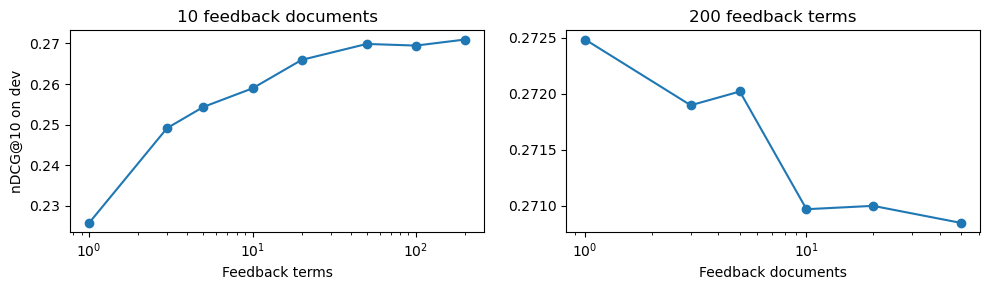

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(FB_TERMS_VALUES, terms_scores, marker="o")
axes[0].set_xscale("log")
axes[0].set_xlabel("Feedback terms")
axes[0].set_ylabel("nDCG@10 on dev")
axes[0].set_title(f"{FIXED_FB_DOCS} feedback documents")

axes[1].plot(FB_DOCS_VALUES, docs_scores, marker="o")
axes[1].set_xscale("log")
axes[1].set_xlabel("Feedback documents")
axes[1].set_title(f"{best_fb_terms} feedback terms")

plt.tight_layout()
plt.show()

## Similar terms from word vectors
Each query term adds its nearest neighbours in the vector space, and the first few added terms are appended to the query.

In [5]:
word2vec_vectors = gensim.downloader.load("word2vec-google-news-300")
glove_vectors = gensim.downloader.load("glove-wiki-gigaword-300")

In [6]:
MAX_EXPANSION_TERMS = 10
similar_terms_cache = {}


def similar_terms(query_term: str, word_vectors) -> list[str]:
    cache_key = (id(word_vectors), query_term)
    if cache_key not in similar_terms_cache:
        neighbours = word_vectors.most_similar(query_term, topn=MAX_EXPANSION_TERMS, restrict_vocab=200000)
        similar_terms_cache[cache_key] = [similar_term.replace("_", " ") for similar_term, _similarity in neighbours]
    return similar_terms_cache[cache_key]


def expand_query_with_similar_terms(query: str, word_vectors, number_of_terms: int) -> str:
    query_terms = query.lower().split()
    expansion_terms = []

    for query_term in query_terms:
        if query_term not in word_vectors:
            continue
        for similar_term in similar_terms(query_term, word_vectors)[:number_of_terms]:
            if similar_term in query_terms or similar_term in expansion_terms:
                continue
            expansion_terms.append(similar_term)

    expansion_text = " ".join(expansion_terms[:number_of_terms])
    return clean_query_text(f"{query} {expansion_text}")


def expansion_transformer(word_vectors, number_of_terms: int):
    return pt.apply.query(lambda row: expand_query_with_similar_terms(row["query"], word_vectors, number_of_terms))


for query in dev_queries["query"].head(3):
    print(query)
    print(expand_query_with_similar_terms(query, glove_vectors, 5))
    print()

Could an ex employee of a company find themself stranded with shares they cannot sell and a tax bill
Could an ex employee of a company find themself stranded with shares they cannot sell and a tax bill would might if likely not

Better ways to invest money held by my small privately held Canadian corporation
Better ways to invest money held by my small privately held Canadian corporation good get well much even

At what point is it most advantageous to cease depositing into a 401k
At what point is it most advantageous to cease depositing into a 401k where time near here



In [7]:
EXPANSION_TERM_COUNTS = [1, 2, 5, 10]
word_vectors_by_name = {"word2vec": word2vec_vectors, "GloVe": glove_vectors}

expansion_dev_scores = {}
best_term_counts = {}
for vectors_name, word_vectors in word_vectors_by_name.items():
    systems = [expansion_transformer(word_vectors, number_of_terms) >> bm25
               for number_of_terms in EXPANSION_TERM_COUNTS]
    scores = dev_ndcg(systems)

    expansion_dev_scores[vectors_name] = scores
    best_term_counts[vectors_name] = EXPANSION_TERM_COUNTS[scores.index(max(scores))]

pd.DataFrame(expansion_dev_scores, index=EXPANSION_TERM_COUNTS).round(4)

,word2vec,GloVe
1,0.2602,0.2623
2,0.2520,0.2569
5,0.2278,0.2344
10,0.1981,0.2193


## Test results

In [8]:
systems = {
    "BM25": bm25,
    "RM3 BM25": rm3_pipeline(bm25, best_fb_terms, best_fb_docs),
    "word2vec BM25": expansion_transformer(word2vec_vectors, best_term_counts["word2vec"]) >> bm25,
    "GloVe BM25": expansion_transformer(glove_vectors, best_term_counts["GloVe"]) >> bm25,
    "DirichletLM": dirichlet,
    "RM3 DirichletLM": rm3_pipeline(dirichlet, best_fb_terms, best_fb_docs),
}

test_results = pt.Experiment(list(systems.values()), test_queries, test_qrels, RANKING_METRICS,
                             names=list(systems.keys()), round=4)
test_results["query time (ms)"] = [round(milliseconds_per_query(system, test_queries), 1)
                                   for system in systems.values()]
test_results

,name,P@10,R@100,nDCG@5,nDCG@10,nDCG@20,RR@10,query time (ms)
0,BM25,0.0702,0.5524,0.2309,0.2541,0.2788,0.3119,15.0
1,RM3 BM25,0.0696,0.5659,0.2335,0.2543,0.2787,0.3076,48.4
2,word2vec BM25,0.0673,0.5446,0.2173,0.2398,0.2641,0.2957,15.3
3,GloVe BM25,0.0676,0.5496,0.2218,0.2439,0.2691,0.3030,14.7
4,DirichletLM,0.0685,0.5412,0.2388,0.2549,0.2774,0.3199,16.1
5,RM3 DirichletLM,0.0410,0.3192,0.1823,0.1886,0.1989,0.2664,57.7


In [9]:
update_best_parameters({"RM3": {"fb_terms": best_fb_terms, "fb_docs": best_fb_docs}})
save_results(test_results, "02_query_expansion")